<a href="https://colab.research.google.com/github/Udayrajchothave/DA-Mini-Project/blob/main/Churn_Modelling_Using_Adaboost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [2]:
raw= pd.read_csv('Churn_Modelling.csv')

In [3]:
raw.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
raw.shape

(10000, 14)

In [5]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [6]:
raw.isna().sum()

,0
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


In [7]:
df=raw.copy()

In [8]:
x=df.drop(['CustomerId','Surname','Exited'],axis=1)
y=df['Exited']

In [9]:
print(x.value_counts())

RowNumber  CreditScore  Geography  Gender  Age  Tenure  Balance    NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary
9984       613          France     Male    40   4       0.00       1              0          0               151325.24          1
9983       655          Germany    Female  46   7       137145.12  1              1          0               115146.40          1
9982       498          Germany    Male    42   3       152039.70  1              1          1               53445.17           1
9981       741          Spain      Male    35   6       74371.49   1              0          0               99595.67           1
9980       677          France     Female  58   1       90022.85   1              0          1               2988.28            1
                                                                                                                               ..
5          850          Spain      Female  43   2       125510.82  1              1          1 

In [10]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)
print('Train rows: ',len(x_train))
print('Test rows: ',len(x_test))


Train rows:  8000
Test rows:  2000


In [11]:
# 1. One-hot encode categorical features and drop identifier columns
x_encoded = pd.get_dummies(df.drop(['RowNumber', 'CustomerId', 'Surname', 'Exited'], axis=1), drop_first=True)
y = df['Exited']

# 2. Re-split the encoded dataset into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x_encoded, y, test_size=0.2, random_state=42, stratify=y)

# 3. Fit and evaluate the model
single_stump = DecisionTreeClassifier(max_depth=1, random_state=42)
single_stump.fit(x_train, y_train)

stump_prediction = single_stump.predict(x_test)
print("Stump Accuracy: ", accuracy_score(y_test, stump_prediction))

Stump Accuracy:  0.7965


[Text(0.5, 0.75, 'Age <= 42.5\ngini = 0.324\nsamples = 8000\nvalue = [6370, 1630]'),
 Text(0.25, 0.25, 'gini = 0.208\nsamples = 5706\nvalue = [5033, 673]'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.486\nsamples = 2294\nvalue = [1337, 957]'),
 Text(0.625, 0.5, '  False')]

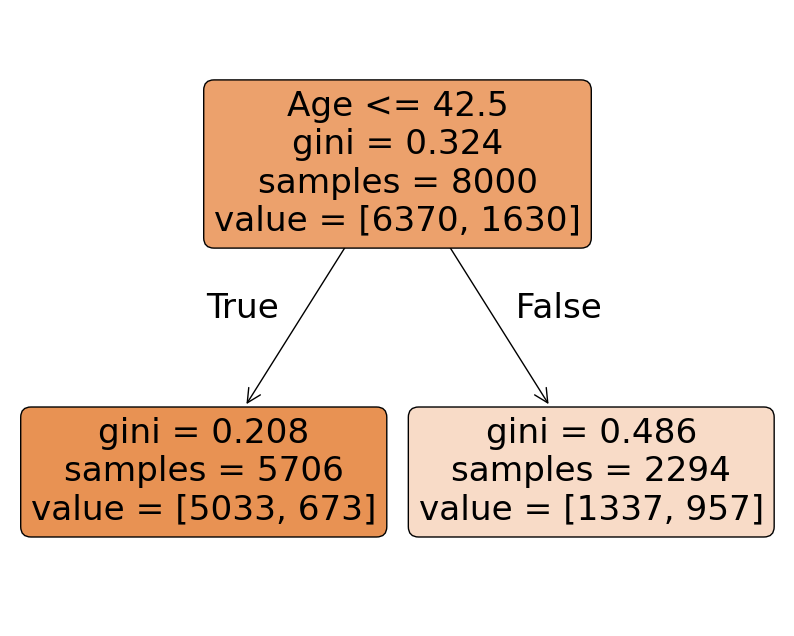

In [12]:
plt.figure(figsize=(10, 8))
plot_tree(single_stump, feature_names=x_train.columns, filled=True, rounded=True)


#### FINAL MODEL TRAINING: Optimized AdaBoost Classifier

 Based on our Grid Search optimization, the best parameters are:
 - Base Estimator: DecisionTreeClassifier(max_depth=3)
 - Learning Rate: 0.1
 - Number of Estimators: 500

In [13]:
# Initialize the optimal base estimator
optimal_base = DecisionTreeClassifier(max_depth=3, random_state=42)

# Initialize and train the final AdaBoost model
model = AdaBoostClassifier(
    estimator=optimal_base,
    n_estimators=500,
    learning_rate=0.1,
    random_state=42
)
model.fit(x_train, y_train)

AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=3,
                                                    random_state=42),
                   learning_rate=0.1, n_estimators=500, random_state=42)

### Model Performance Analysis & Visualizations
Below we visualize the results of our final model using a Confusion Matrix to inspect True Positives, True Negatives, False Positives, and False Negatives.

In [14]:
predictions = model.predict(x_test)

# Print metrics
print(f"Optimized AdaBoost Test Accuracy: {accuracy_score(y_test, predictions):.4f}\n")
print("Classification Report:\n", classification_report(y_test, predictions))

Optimized AdaBoost Test Accuracy: 0.8675

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.97      0.92      1593
           1       0.79      0.48      0.59       407

    accuracy                           0.87      2000
   macro avg       0.83      0.72      0.76      2000
weighted avg       0.86      0.87      0.85      2000



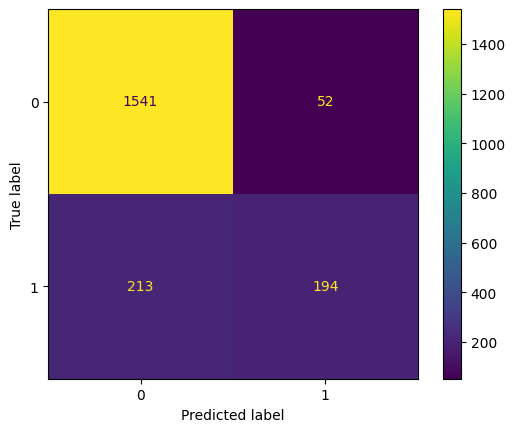

In [15]:
ConfusionMatrixDisplay.from_predictions( y_test,predictions)

In [16]:
stump_details = pd.DataFrame({
    'Round': range(1, len(model.estimators_) + 1),
    'Weighted error': model.estimator_errors_[:len(model.estimators_)],
    'Voting weight': model.estimator_weights_[:len(model.estimators_)]
})
display(stump_details.head(10).round(4))

,Round,Weighted error,Voting weight
0,1,0.1596,0.1661
1,2,0.1816,0.1506
2,3,0.2000,0.1386
3,4,0.2256,0.1234
4,5,0.2358,0.1176
5,6,0.2576,0.1058
6,7,0.2657,0.1017
7,8,0.2618,0.1036
8,9,0.2909,0.0891
9,10,0.3113,0.0794


In [17]:
cv_scores=cross_val_score(model,x_train,y_train,cv=5,scoring='accuracy')
print(cv_scores)
print(cv_scores.mean())

[0.858125 0.868125 0.84875  0.8575   0.870625]
0.860625


In [18]:
from sklearn.model_selection import GridSearchCV

# Define a parameter grid to optimize AdaBoost with slightly deeper base estimators
param_grid = {
    'estimator': [
        DecisionTreeClassifier(max_depth=2, random_state=42),
        DecisionTreeClassifier(max_depth=3, random_state=42)
    ],
    'n_estimators': [100, 200, 500],
    'learning_rate': [0.05, 0.1, 0.2]
}

# Set up Grid Search with 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=AdaBoostClassifier(random_state=42),
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)

# Fit the grid search on the training data
grid_search.fit(x_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_:.4f}")

Best Parameters: {'estimator': DecisionTreeClassifier(max_depth=3, random_state=42), 'learning_rate': 0.1, 'n_estimators': 500}
Best Cross-Validation Accuracy: 0.8606


### Evaluate the best model on the test set


Optimized AdaBoost Test Accuracy: 0.8675

Classification Report:
               precision    recall  f1-score   support

           0       0.88      0.97      0.92      1593
           1       0.79      0.48      0.59       407

    accuracy                           0.87      2000
   macro avg       0.83      0.72      0.76      2000
weighted avg       0.86      0.87      0.85      2000



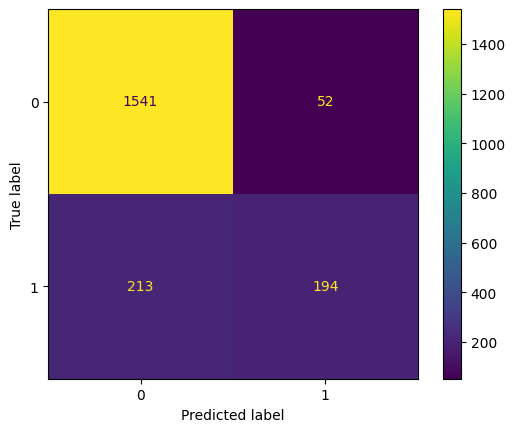

In [19]:
best_model = grid_search.best_estimator_
best_preds = best_model.predict(x_test)

print("Optimized AdaBoost Test Accuracy:", accuracy_score(y_test, best_preds))
print("\nClassification Report:\n", classification_report(y_test, best_preds))
ConfusionMatrixDisplay.from_predictions(y_test, best_preds)